# Метод Монте-Карло: простой пример

Решаем уравнение
$$a(x)f'' + b(x)f' + (c(x)-\lambda)f = -g(x),\qquad x\in\mathbb R,$$
солвером `mc_solver.solve`. Схема работы метода описана в `README.md`.

Для проверки возьмём задачу с известным ответом: $a=1$, $b=c=0$, $\lambda=2$ и точное решение $f(x)=e^{-x^2}$. Тогда правая часть
$$g(x) = -\bigl(f'' - 2f\bigr) = (4-4x^2)\,e^{-x^2}.$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from mc_solver import solve, paths_for_tolerance

## 1. Задаём задачу

Коэффициенты — функции от numpy-массива. Константы можно задавать как `lambda x: 1.0`.

In [2]:
a = lambda x: 1.0
b = lambda x: 0.0
c = lambda x: 0.0
g = lambda x: (4 - 4 * x**2) * np.exp(-x**2)
lam = 2.0                                  # нужно lam > sup|c|

f_exact = lambda x: np.exp(-x**2)          # для проверки

## 2. Значение в одной точке

`M` — число траекторий, `dt` — шаг по времени, `seed` — зерно генератора (с ним результат повторяется).

In [3]:
res = solve(a, b, c, g, lam, x0=0.0, M=20_000, dt=0.005, seed=1)

print(f"Монте-Карло: {res.value:.4f} ± {res.ci95:.4f}  (95%)")
print(f"точное:      {f_exact(0.0):.4f}")
print(f"T = {res.T:.2f}, шагов {round(res.T / res.dt)}, время {res.seconds:.1f} с")

Монте-Карло: 1.0036 ± 0.0055  (95%)
точное:      1.0000
T = 4.61, шагов 921, время 0.4 с


## 3. Несколько точек

Если передать массив `x0`, вернётся список результатов — по одному на точку. Каждая точка считается отдельно.

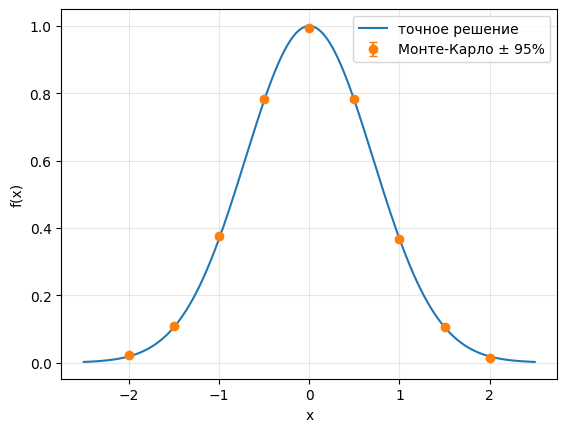

наибольшая ошибка: 0.0077258135449084775


In [4]:
xs = np.linspace(-2, 2, 9)
results = solve(a, b, c, g, lam, x0=xs, M=20_000, dt=0.005, seed=2)

values = np.array([r.value for r in results])
ci = np.array([r.ci95 for r in results])

grid = np.linspace(-2.5, 2.5, 400)
plt.plot(grid, f_exact(grid), label="точное решение")
plt.errorbar(xs, values, yerr=ci, fmt="o", capsize=3, label="Монте-Карло ± 95%")
plt.xlabel("x"); plt.ylabel("f(x)"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

print("наибольшая ошибка:", np.max(np.abs(values - f_exact(xs))))

## 4. Сколько траекторий нужно для заданной точности

Статистическая ошибка убывает как $1/\sqrt M$. По пробному прогону `paths_for_tolerance` оценивает, сколько траекторий нужно, чтобы полуширина 95%-интервала стала не больше `tol`.

In [5]:
pilot = solve(a, b, c, g, lam, x0=0.0, M=5_000, dt=0.005, seed=3)
for tol in (1e-2, 3e-3, 1e-3):
    print(f"tol = {tol:g}:  M ≈ {paths_for_tolerance(pilot.stderr, pilot.M, tol):,}")

tol = 0.01:  M ≈ 5,997
tol = 0.003:  M ≈ 66,626
tol = 0.001:  M ≈ 599,632


## 5. Проверка шага `dt`

Кроме шума есть смещение от шага `dt`; увеличением `M` оно не убирается. Проверка: посчитать с `dt` и `dt/2`. Если результаты различаются больше, чем на шум, шаг надо уменьшать.

В этой задаче коэффициенты постоянны, и смещение мало. При переменных коэффициентах оно заметнее: примерно пропорционально `dt`.

In [6]:
for dt in (0.02, 0.01, 0.005):
    r = solve(a, b, c, g, lam, x0=0.0, M=40_000, dt=dt, seed=4)
    print(f"dt = {dt:<6} f(0) = {r.value:.4f} ± {r.ci95:.4f}   ошибка {abs(r.value - 1):.4f}")

dt = 0.02   f(0) = 1.0023 ± 0.0039   ошибка 0.0023


dt = 0.01   f(0) = 1.0023 ± 0.0039   ошибка 0.0023


dt = 0.005  f(0) = 1.0026 ± 0.0039   ошибка 0.0026


## 6. Шаблон для своей задачи

Подставьте свои $a, b, c, g, \lambda$ и точку. Порядок действий:
1. пробный прогон с небольшим `M`;
2. проверка `dt` (п. 5);
3. по `paths_for_tolerance` — нужное `M` и окончательный расчёт.

In [7]:
a = lambda x: 1 + 0.3 * np.sin(np.pi * x)     # a(x) > 0
b = lambda x: 0.4 * np.cos(np.pi * x)
c = lambda x: 0.3 * np.tanh(x)
g = lambda x: np.exp(-x**2)
lam = 1.5                                     # > sup|c| = 0.3

res = solve(a, b, c, g, lam, x0=0.0, M=10_000, dt=0.01, seed=5)
print(f"f(0) ≈ {res.value:.4f} ± {res.ci95:.4f}, время {res.seconds:.1f} с")

f(0) ≈ 0.4123 ± 0.0022, время 0.5 с
